<a href="https://colab.research.google.com/github/Haritha147/Deep-learning-/blob/main/C02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Final training accuracy: 1.0
Final validation accuracy: 0.6792
Best validation accuracy: 0.717 at epoch 10
Test accuracy of best-validation model: 0.7667
Gap (train - validation) at final epoch: 0.3208
Diagnosis: overfitting (large gap between training and validation accuracy)


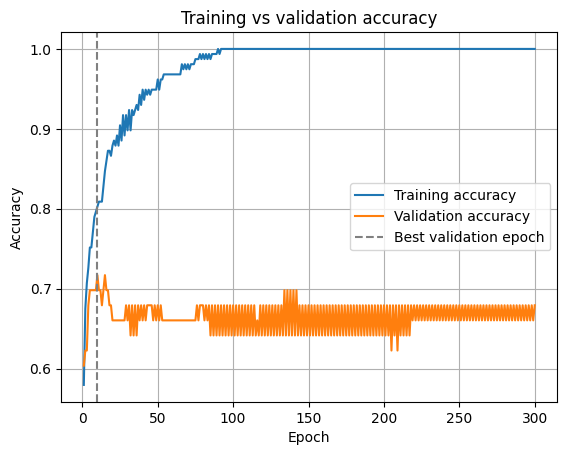


L2 regularization (alpha) search, selected on validation accuracy:
alpha=0.0001  train=1.0000  validation=0.6792
alpha=0.001   train=1.0000  validation=0.6792
alpha=0.01    train=1.0000  validation=0.6792
alpha=0.1     train=1.0000  validation=0.6792
alpha=1.0     train=1.0000  validation=0.6981
Selected alpha: 1.0
Test accuracy of regularized model: 0.7778

Suggested improvements:
1. Add L2 regularization (alpha parameter of MLPClassifier)
2. Use early stopping, selected on a validation split
3. Reduce network size
4. Collect more training data


In [2]:
# Program 17: Overfitting analysis for a neural network predicting exam performance

import copy
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore", category=UserWarning)

X, y = make_classification(n_samples=300, n_features=20, n_informative=5,
                           n_redundant=2, flip_y=0.1, random_state=7)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=7)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=7)

model = MLPClassifier(hidden_layer_sizes=(128, 128), activation="relu",
                      max_iter=1, warm_start=True, random_state=7)

epochs = 300
train_acc, val_acc = [], []
best_val, best_epoch, best_model = -1, 0, None
for epoch in range(1, epochs + 1):
    model.fit(X_fit, y_fit)
    tr = accuracy_score(y_fit, model.predict(X_fit))
    va = accuracy_score(y_val, model.predict(X_val))
    train_acc.append(tr)
    val_acc.append(va)
    if va > best_val:
        best_val, best_epoch, best_model = va, epoch, copy.deepcopy(model)

print("Final training accuracy:", round(train_acc[-1], 4))
print("Final validation accuracy:", round(val_acc[-1], 4))
print("Best validation accuracy:", round(best_val, 4), "at epoch", best_epoch)
print("Test accuracy of best-validation model:",
      round(accuracy_score(y_test, best_model.predict(X_test)), 4))
print("Gap (train - validation) at final epoch:", round(train_acc[-1] - val_acc[-1], 4))

if train_acc[-1] - val_acc[-1] > 0.1:
    print("Diagnosis: overfitting (large gap between training and validation accuracy)")
else:
    print("Diagnosis: no major overfitting")

plt.plot(range(1, epochs + 1), train_acc, label="Training accuracy")
plt.plot(range(1, epochs + 1), val_acc, label="Validation accuracy")
plt.axvline(best_epoch, color="gray", linestyle="--", label="Best validation epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs validation accuracy")
plt.legend()
plt.grid(True)
plt.show()

best_alpha, best_reg_val, best_reg_model = None, -1, None
print("\nL2 regularization (alpha) search, selected on validation accuracy:")
for alpha in [1e-4, 1e-3, 1e-2, 1e-1, 1.0]:
    reg = MLPClassifier(hidden_layer_sizes=(128, 128), activation="relu",
                        alpha=alpha, max_iter=300, random_state=7)
    reg.fit(X_fit, y_fit)
    tr = accuracy_score(y_fit, reg.predict(X_fit))
    va = accuracy_score(y_val, reg.predict(X_val))
    print(f"alpha={alpha:<7} train={tr:.4f}  validation={va:.4f}")
    if va > best_reg_val:
        best_alpha, best_reg_val, best_reg_model = alpha, va, reg

print("Selected alpha:", best_alpha)
print("Test accuracy of regularized model:",
      round(accuracy_score(y_test, best_reg_model.predict(X_test)), 4))

print("\nSuggested improvements:")
print("1. Add L2 regularization (alpha parameter of MLPClassifier)")
print("2. Use early stopping, selected on a validation split")
print("3. Reduce network size")
print("4. Collect more training data")

 Degree      Fit MSE   Validation MSE
      1       444.43           287.15
      2        60.46            44.88
      3        60.33            43.79
      4        58.54            41.91
      5        57.74            41.51
      6        57.54            40.11
      7        55.03            40.62
      8        54.69            39.59
      9        54.58            39.62
     10        54.47            40.46
     11        53.80            42.45
     12        53.50            42.72

Best degree (lowest validation error): 8
Test MSE of selected degree: 57.76


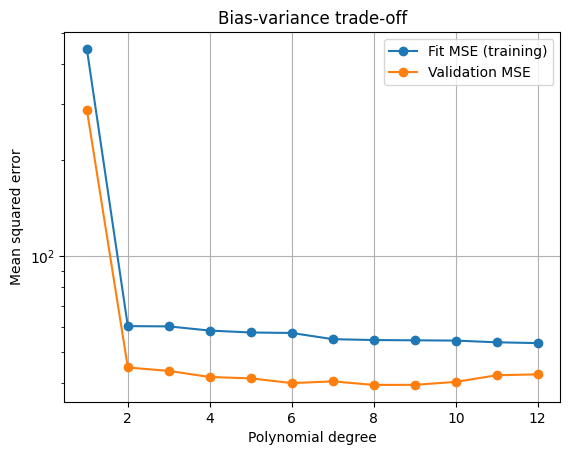

In [3]:
# Program 18: Polynomial regression degrees and the bias-variance trade-off

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(3)
n = 120
area = rng.uniform(0.5, 3.0, n).reshape(-1, 1)
price = 40 * area.ravel() ** 2 - 25 * area.ravel() + 30 + rng.normal(0, 8, n)

X_train, X_test, y_train, y_test = train_test_split(area, price, test_size=0.3, random_state=3)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=3)

degrees = list(range(1, 13))
fit_err, val_err = [], []
for d in degrees:
    poly = PolynomialFeatures(degree=d)
    X_f = poly.fit_transform(X_fit)
    X_v = poly.transform(X_val)
    model = LinearRegression().fit(X_f, y_fit)
    fit_err.append(mean_squared_error(y_fit, model.predict(X_f)))
    val_err.append(mean_squared_error(y_val, model.predict(X_v)))

print(f"{'Degree':>7} {'Fit MSE':>12} {'Validation MSE':>16}")
for d, fe, ve in zip(degrees, fit_err, val_err):
    print(f"{d:>7} {fe:>12.2f} {ve:>16.2f}")

best = degrees[int(np.argmin(val_err))]
print("\nBest degree (lowest validation error):", best)

poly_best = PolynomialFeatures(degree=best)
X_train_all = poly_best.fit_transform(X_train)
X_test_best = poly_best.transform(X_test)
final_model = LinearRegression().fit(X_train_all, y_train)
test_mse = mean_squared_error(y_test, final_model.predict(X_test_best))
print("Test MSE of selected degree:", round(test_mse, 2))

for d, fe, ve in zip(degrees, fit_err, val_err):
    if fe < min(fit_err) * 1.05 and ve > 2 * min(val_err):
        print("Degree", d, "onward: variance dominates (validation error more than doubles)")
        break

plt.plot(degrees, fit_err, marker="o", label="Fit MSE (training)")
plt.plot(degrees, val_err, marker="o", label="Validation MSE")
plt.xlabel("Polynomial degree")
plt.ylabel("Mean squared error")
plt.title("Bias-variance trade-off")
plt.legend()
plt.grid(True)
plt.yscale("log")
plt.show()

     alpha    L1 val RMSE  L1 nonzero    L2 val RMSE
     0.001        8354.56           7        8354.56
     0.003        8354.56           7        8354.56
     0.010        8354.56           7        8354.56
     0.032        8354.56           7        8354.54
     0.100        8354.55           7        8354.49
     0.316        8354.51           7        8354.36
     1.000        8354.40           7        8354.21
     3.162        8354.06           7        8356.44
    10.000        8353.02           7        8388.61
    31.623        8349.99           7        8691.33
   100.000        8343.31           7       10543.07
   316.228        8360.44           5       15786.91
  1000.000        8606.66           4       21999.83

Selected alpha (validation RMSE): L1 = 100.0  L2 = 1.0

Model                                  RMSE        MAE       R2
Linear (no regularization)          8028.33    6368.13   0.9221
L1 Lasso (alpha=100)                8059.32    6396.29   0.9215
L2 Ridge 

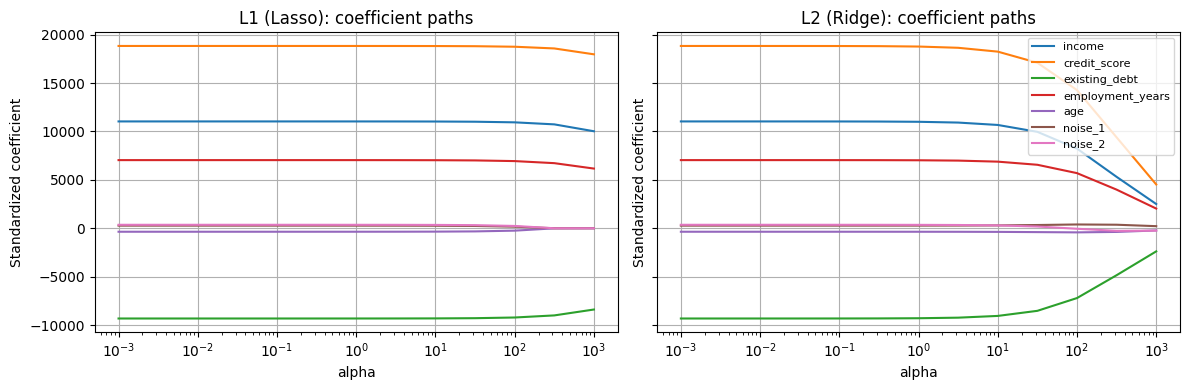

In [4]:
# Program 19: L1 and L2 regularization for loan amount prediction

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

rng = np.random.default_rng(5)
n = 500
income = rng.uniform(20000, 120000, n)
credit_score = rng.uniform(300, 850, n)
existing_debt = rng.uniform(0, 50000, n)
employment_years = rng.uniform(0, 30, n)
age = rng.uniform(21, 70, n)
noise_1 = rng.normal(0, 1, n)
noise_2 = rng.normal(0, 1, n)
loan = (0.4 * income + 120 * credit_score - 0.6 * existing_debt
        + 800 * employment_years + rng.normal(0, 8000, n))

features = ["income", "credit_score", "existing_debt", "employment_years", "age", "noise_1", "noise_2"]
X = np.column_stack([income, credit_score, existing_debt, employment_years, age, noise_1, noise_2])
y = loan

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=5)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=5)

scaler = StandardScaler().fit(X_fit)
Xf, Xv = scaler.transform(X_fit), scaler.transform(X_val)

alphas = np.logspace(-3, 3, 13)
l1_val, l2_val, l1_coefs, l2_coefs = [], [], [], []
for a in alphas:
    lasso = Lasso(alpha=a, max_iter=50000).fit(Xf, y_fit)
    ridge = Ridge(alpha=a).fit(Xf, y_fit)
    l1_val.append(rmse(y_val, lasso.predict(Xv)))
    l2_val.append(rmse(y_val, ridge.predict(Xv)))
    l1_coefs.append(lasso.coef_)
    l2_coefs.append(ridge.coef_)

print(f"{'alpha':>10} {'L1 val RMSE':>14} {'L1 nonzero':>11} {'L2 val RMSE':>14}")
for i, a in enumerate(alphas):
    nz = int(np.sum(l1_coefs[i] != 0))
    print(f"{a:>10.3f} {l1_val[i]:>14.2f} {nz:>11d} {l2_val[i]:>14.2f}")

best_a1 = alphas[int(np.argmin(l1_val))]
best_a2 = alphas[int(np.argmin(l2_val))]
print("\nSelected alpha (validation RMSE): L1 =", round(best_a1, 4), " L2 =", round(best_a2, 4))

scaler_all = StandardScaler().fit(X_train)
Xtr, Xte = scaler_all.transform(X_train), scaler_all.transform(X_test)

models = {
    "Linear (no regularization)": LinearRegression(),
    f"L1 Lasso (alpha={best_a1:.3g})": Lasso(alpha=best_a1, max_iter=50000),
    f"L2 Ridge (alpha={best_a2:.3g})": Ridge(alpha=best_a2),
}

print(f"\n{'Model':<32} {'RMSE':>10} {'MAE':>10} {'R2':>8}")
fitted = {}
for name, m in models.items():
    m.fit(Xtr, y_train)
    pred = m.predict(Xte)
    fitted[name] = m
    print(f"{name:<32} {rmse(y_test, pred):>10.2f} {mean_absolute_error(y_test, pred):>10.2f} "
          f"{r2_score(y_test, pred):>8.4f}")

print(f"\n{'Feature':<20} {'Linear':>12} {'L1':>12} {'L2':>12}")
names = list(models.keys())
for j, f in enumerate(features):
    row = [fitted[nm].coef_[j] for nm in names]
    print(f"{f:<20} {row[0]:>12.2f} {row[1]:>12.2f} {row[2]:>12.2f}")

print("\nL1 zeroed features:", [f for j, f in enumerate(features) if fitted[names[1]].coef_[j] == 0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
l1_arr, l2_arr = np.array(l1_coefs), np.array(l2_coefs)
for j, f in enumerate(features):
    axes[0].semilogx(alphas, l1_arr[:, j], label=f)
    axes[1].semilogx(alphas, l2_arr[:, j], label=f)
axes[0].set_title("L1 (Lasso): coefficient paths")
axes[1].set_title("L2 (Ridge): coefficient paths")
for ax in axes:
    ax.set_xlabel("alpha")
    ax.set_ylabel("Standardized coefficient")
    ax.grid(True)
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

 Learning rate  Epochs run  Final train MSE  Final val MSE  Epochs to 0.1 val MSE
         1e-05         200           0.8973         1.0193            not reached
        0.0001         200           0.6935         0.7914            not reached
         0.001         200           0.0577         0.0665                    146
          0.01         200           0.0292         0.0405                     15
           0.1         200           0.0234         0.0377                      2
             1         200           1.1320         1.3173            not reached

Selected learning rate (lowest final validation MSE): 0.1
Test MSE of selected learning rate: 236.37


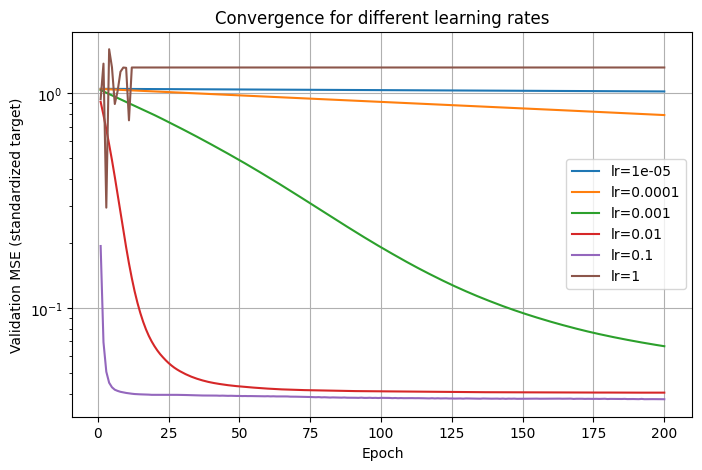

In [5]:
# Program 20: Effect of learning rate on convergence of a demand prediction network

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(11)
n = 600
price = rng.uniform(5, 50, n)
promotion = rng.integers(0, 2, n)
season = rng.integers(0, 4, n)
competitor_price = rng.uniform(5, 50, n)
X = np.column_stack([price, promotion, season, competitor_price])
demand = (500 - 6 * price + 80 * promotion + 25 * season + 2 * competitor_price
          + rng.normal(0, 15, n))

X_train, X_test, y_train, y_test = train_test_split(X, demand, test_size=0.2, random_state=11)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=11)

scaler = StandardScaler().fit(X_fit)
Xf, Xv = scaler.transform(X_fit), scaler.transform(X_val)
y_mean, y_std = y_fit.mean(), y_fit.std()
yf, yv = (y_fit - y_mean) / y_std, (y_val - y_mean) / y_std

learning_rates = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
epochs = 200
results = {}

for lr in learning_rates:
    model = MLPRegressor(hidden_layer_sizes=(32, 16), activation="relu", solver="sgd",
                         learning_rate_init=lr, batch_size=32, max_iter=1,
                         warm_start=True, random_state=11, momentum=0.0)
    train_loss, val_loss = [], []
    for epoch in range(epochs):
        model.fit(Xf, yf)
        tr = mean_squared_error(yf, model.predict(Xf))
        va = mean_squared_error(yv, model.predict(Xv))
        if not np.isfinite(va):
            tr = va = float("nan")
            train_loss.append(tr)
            val_loss.append(va)
            break
        train_loss.append(tr)
        val_loss.append(va)
    results[lr] = (train_loss, val_loss)

print(f"{'Learning rate':>14} {'Epochs run':>11} {'Final train MSE':>16} {'Final val MSE':>14} {'Epochs to 0.1 val MSE':>22}")
for lr in learning_rates:
    tl, vl = results[lr]
    reached = next((i + 1 for i, v in enumerate(vl) if np.isfinite(v) and v <= 0.1), None)
    final_t = tl[-1] if np.isfinite(tl[-1]) else float("nan")
    final_v = vl[-1] if np.isfinite(vl[-1]) else float("nan")
    print(f"{lr:>14g} {len(vl):>11d} {final_t:>16.4f} {final_v:>14.4f} "
          f"{str(reached) if reached else 'not reached':>22}")

finite = {lr: results[lr][1][-1] for lr in learning_rates if np.isfinite(results[lr][1][-1])}
best_lr = min(finite, key=finite.get)
print("\nSelected learning rate (lowest final validation MSE):", best_lr)

final = MLPRegressor(hidden_layer_sizes=(32, 16), activation="relu", solver="sgd",
                     learning_rate_init=best_lr, batch_size=32, max_iter=epochs,
                     random_state=11, momentum=0.0)
final.fit(Xf, yf)
Xte = scaler.transform(X_test)
pred = final.predict(Xte) * y_std + y_mean
print("Test MSE of selected learning rate:", round(mean_squared_error(y_test, pred), 2))

plt.figure(figsize=(8, 5))
for lr in learning_rates:
    tl, vl = results[lr]
    plt.plot(range(1, len(vl) + 1), vl, label=f"lr={lr:g}")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE (standardized target)")
plt.title("Convergence for different learning rates")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
# Program 21: Floating-point precision errors across numerical data types

import numpy as np
from fractions import Fraction

def exact_sum_of_tenths(n):
    return Fraction(1, 10) * n

print("Summing 0.1 repeatedly (exact value = n/10):")
print(f"{'n':>10} {'float16':>14} {'float32':>14} {'float64':>14} {'exact':>14}")
for n in [10, 1000, 100000]:
    s16 = np.float16(0)
    s32 = np.float32(0)
    s64 = np.float64(0)
    for _ in range(n):
        s16 = np.float16(s16 + np.float16(0.1))
        s32 = np.float32(s32 + np.float32(0.1))
        s64 = np.float64(s64 + np.float64(0.1))
    exact = float(exact_sum_of_tenths(n))
    print(f"{n:>10} {float(s16):>14.4f} {float(s32):>14.4f} {float(s64):>14.6f} {exact:>14.6f}")

print("\nRelative error of each type after 100000 additions of 0.1:")
exact = 100000 / 10
for dtype in (np.float16, np.float32, np.float64):
    total = dtype(0)
    step = dtype(0.1)
    for _ in range(100000):
        total = dtype(total + step)
    err = abs(float(total) - exact) / exact
    print(f"{dtype.__name__:>10}: total = {float(total):.6f}, relative error = {err:.2e}")

print("\nCatastrophic cancellation: (1 + x) - 1 for small x")
for x in [1e-8, 1e-12, 1e-16]:
    for dtype in (np.float32, np.float64):
        xv = dtype(x)
        computed = (dtype(1) + xv) - dtype(1)
        rel = abs(float(computed) - x) / x
        print(f"x = {x:.0e}, {dtype.__name__}: computed = {float(computed):.3e}, relative error = {rel:.2e}")

print("\nOverflow and underflow limits:")
for dtype in (np.float16, np.float32, np.float64):
    info = np.finfo(dtype)
    print(f"{dtype.__name__:>8}: max = {info.max:.3e}, smallest normal = {info.tiny:.3e}, "
          f"machine epsilon = {info.eps:.3e}")

print("\nOverflow demonstration:")
big = np.float16(60000)
print("float16 60000 * 2 =", big * np.float16(2), "(overflows to inf)")
print("float64 60000 * 2 =", np.float64(60000) * 2)

print("\nUnderflow demonstration:")
tiny = np.float16(1e-5)
print("float16 product of tiny values 1e-5 * 1e-5 =", tiny * tiny)
print("float64 product of same values =", np.float64(1e-5) * np.float64(1e-5))

print("\nLarge and small mixed sum (order of addition matters):")
values = [1e16, 1.0, -1e16]
print("(1e16 + 1) - 1e16 in float64 =", (values[0] + values[1]) + values[2])
print("1e16 + (1 - 1e16) in float64 =", values[0] + (values[1] + values[2]))
print("Exact result is 1.0 when computed as Fraction:",
      float(Fraction(10**16) + Fraction(1) - Fraction(10**16)))

print("\nConclusion: float16 accumulates large error quickly and overflows past 65504;")
print("float32 is adequate for many tasks but loses precision at large magnitudes;")
print("float64 has about 16 significant decimal digits and is the default for scientific work.")

Summing 0.1 repeatedly (exact value = n/10):
         n        float16        float32        float64          exact
        10         1.0000         1.0000       1.000000       1.000000
      1000       105.1875        99.9990     100.000000     100.000000
    100000       256.0000      9998.5566   10000.000000   10000.000000

Relative error of each type after 100000 additions of 0.1:
   float16: total = 256.000000, relative error = 9.74e-01
   float32: total = 9998.556641, relative error = 1.44e-04
   float64: total = 10000.000000, relative error = 1.88e-12

Catastrophic cancellation: (1 + x) - 1 for small x
x = 1e-08, float32: computed = 0.000e+00, relative error = 1.00e+00
x = 1e-08, float64: computed = 1.000e-08, relative error = 6.08e-09
x = 1e-12, float32: computed = 0.000e+00, relative error = 1.00e+00
x = 1e-12, float64: computed = 1.000e-12, relative error = 8.89e-05
x = 1e-16, float32: computed = 0.000e+00, relative error = 1.00e+00
x = 1e-16, float64: computed = 0.000e+00, 

/tmp/ipykernel_5098/1929172907.py:48: RuntimeWarning: overflow encountered in scalar multiply
  print("float16 60000 * 2 =", big * np.float16(2), "(overflows to inf)")


In [9]:
# Program 22: Grid search, random search, and Bayesian optimization for disease risk

import numpy as np
import time
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from scipy.stats import randint, uniform

X, y = make_classification(n_samples=800, n_features=20, n_informative=8,
                           n_redundant=4, weights=[0.8, 0.2], flip_y=0.05, random_state=21)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=21)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=21)

base = RandomForestClassifier(random_state=21, n_jobs=-1)

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 8, None],
    "min_samples_leaf": [1, 2, 5, 10],
}
grid_size = 3 * 4 * 4

start = time.time()
grid = GridSearchCV(base, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
grid_time = time.time() - start

param_dist = {
    "n_estimators": randint(50, 201),
    "max_depth": [3, 5, 8, None],
    "min_samples_leaf": randint(1, 11),
}
budget = grid_size

start = time.time()
rand = RandomizedSearchCV(base, param_dist, n_iter=budget, cv=cv,
                          scoring="roc_auc", random_state=21, n_jobs=-1)
rand.fit(X_train, y_train)
rand_time = time.time() - start

try:
    from skopt import BayesSearchCV
    from skopt.space import Integer, Categorical
    bayes_space = {
        "n_estimators": Integer(50, 200),
        "max_depth": Categorical([3, 5, 8, None]),
        "min_samples_leaf": Integer(1, 10),
    }
    start = time.time()
    bayes = BayesSearchCV(base, bayes_space, n_iter=budget, cv=cv,
                          scoring="roc_auc", random_state=21, n_jobs=-1)
    bayes.fit(X_train, y_train)
    bayes_time = time.time() - start
    bayes_name = "Bayesian (scikit-optimize)"
except ImportError:
    print("scikit-optimize not installed. Run: !pip install scikit-optimize")
    raise

print(f"{'Method':<28} {'Evaluations':>12} {'Best CV AUC':>12} {'Time (s)':>10} {'Test AUC':>10}")
for name, search, t, evals in [
    ("Grid search", grid, grid_time, grid_size),
    ("Random search", rand, rand_time, budget),
    (bayes_name, bayes, bayes_time, budget),
]:
    test_auc = roc_auc_score(y_test, search.best_estimator_.predict_proba(X_test)[:, 1])
    print(f"{name:<28} {evals:>12d} {search.best_score_:>12.4f} {t:>10.2f} {test_auc:>10.4f}")
    print(f"{'':<28} best params: {search.best_params_}")

print("\nEffectiveness: Test AUC differences are small on this data, so the CV scores")
print("and the time per method are the main basis for comparing the techniques.")

scikit-optimize not installed. Run: !pip install scikit-optimize


ModuleNotFoundError: No module named 'skopt'

Training: average episode reward, first 100 episodes = -663.5
Training: average episode reward, last 100 episodes  = -184.6

Controller                                    Mean total wait        Std
Fixed-time (switch every 20 steps)                      777.4      132.4
Queue rule (switch if other queue longer)               341.7       26.0
Reinforcement learning (greedy)                         171.2       22.9

Learned action when green = North-South (keep = 0, switch = 1):
q_NS \ q_EW    0    2    4    6    8   10
          0    0    1    1    1    1    1
          2    0    0    0    0    1    1
          4    0    0    0    1    1    1
          6    0    0    0    1    1    1
          8    0    0    1    1    1    1
         10    0    0    0    0    1    0


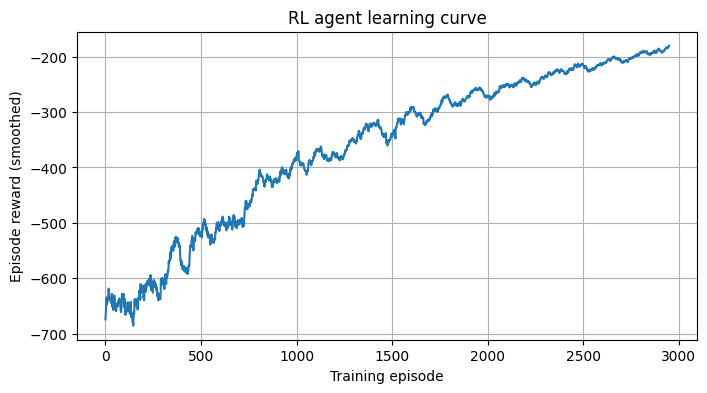

In [8]:
# Program 23: Reinforcement learning agent for adaptive traffic signal control

import numpy as np
import matplotlib.pyplot as plt

MAX_Q = 10
EPISODE_LEN = 200
SATURATION = 3

class TrafficEnv:
    def __init__(self, arrival_ns=0.35, arrival_ew=0.30, seed=0):
        self.arrival = {0: arrival_ns, 1: arrival_ew}
        self.rng = np.random.default_rng(seed)

    def reset(self):
        self.q = [0, 0]
        self.green = 0
        self.t = 0
        self.total_wait = 0
        return self._state()

    def _state(self):
        return (min(self.q[0], MAX_Q), min(self.q[1], MAX_Q), self.green)

    def step(self, action):
        lost = False
        if action == 1:
            self.green = 1 - self.green
            lost = True
        for d in (0, 1):
            self.q[d] += self.rng.poisson(self.arrival[d])
        if not lost:
            discharged = min(SATURATION, self.q[self.green])
            self.q[self.green] -= discharged
        waiting = sum(self.q)
        self.total_wait += waiting
        self.t += 1
        done = self.t >= EPISODE_LEN
        return self._state(), -waiting, done

def train(episodes=3000, alpha=0.1, gamma=0.95, eps_start=1.0, eps_end=0.05, seed=1):
    Q = np.zeros((MAX_Q + 1, MAX_Q + 1, 2, 2))
    rng = np.random.default_rng(seed)
    env = TrafficEnv(seed=seed)
    rewards = []
    for ep in range(episodes):
        eps = eps_start + (eps_end - eps_start) * ep / (episodes - 1)
        s = env.reset()
        done = False
        ep_reward = 0
        while not done:
            if rng.random() < eps:
                a = int(rng.integers(2))
            else:
                a = int(np.argmax(Q[s]))
            s2, r, done = env.step(a)
            target = r + (0 if done else gamma * np.max(Q[s2]))
            Q[s][a] += alpha * (target - Q[s][a])
            s = s2
            ep_reward += r
        rewards.append(ep_reward)
    return Q, rewards

def fixed_time_policy(s, env):
    return 1 if env.t > 0 and env.t % 20 == 0 else 0

def queue_rule_policy(s, env):
    current = s[2]
    cur_queue = s[current]
    other_queue = s[1 - current]
    return 1 if other_queue > cur_queue + 2 else 0

def make_rl_policy(Q):
    def policy(s, env):
        return int(np.argmax(Q[s]))
    return policy

def evaluate(policy, episodes=50, base_seed=10000):
    waits = []
    for i in range(episodes):
        env = TrafficEnv(seed=base_seed + i)
        s = env.reset()
        done = False
        while not done:
            a = policy(s, env)
            s, r, done = env.step(a)
        waits.append(env.total_wait)
    return np.mean(waits), np.std(waits)

Q, rewards = train()

print("Training: average episode reward, first 100 episodes =",
      round(np.mean(rewards[:100]), 1))
print("Training: average episode reward, last 100 episodes  =",
      round(np.mean(rewards[-100:]), 1))

rl_policy = make_rl_policy(Q)
results = {
    "Fixed-time (switch every 20 steps)": evaluate(fixed_time_policy),
    "Queue rule (switch if other queue longer)": evaluate(queue_rule_policy),
    "Reinforcement learning (greedy)": evaluate(rl_policy),
}

print(f"\n{'Controller':<44} {'Mean total wait':>16} {'Std':>10}")
for name, (mean_w, std_w) in results.items():
    print(f"{name:<44} {mean_w:>16.1f} {std_w:>10.1f}")

print("\nLearned action when green = North-South (keep = 0, switch = 1):")
levels = [0, 2, 4, 6, 8, 10]
print("q_NS \\ q_EW " + " ".join(f"{q:>4}" for q in levels))
for q_ns in levels:
    row = []
    for q_ew in levels:
        row.append(f"{int(np.argmax(Q[(q_ns, q_ew, 0)])):>4}")
    print(f"{q_ns:>11} " + " ".join(row))

plt.figure(figsize=(8, 4))
window = 50
smoothed = np.convolve(rewards, np.ones(window) / window, mode="valid")
plt.plot(smoothed)
plt.xlabel("Training episode")
plt.ylabel("Episode reward (smoothed)")
plt.title("RL agent learning curve")
plt.grid(True)
plt.show()

In [ ]:
# Program 24: Single-layer perceptron for loan eligibility

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

rng = np.random.default_rng(24)
n = 300
income = rng.uniform(20, 150, n)
credit = rng.uniform(300, 850, n)

income_s = (income - income.mean()) / income.std()
credit_s = (credit - credit.mean()) / credit.std()
X = np.column_stack([income_s, credit_s])

eligible = (0.6 * income_s + 0.8 * credit_s + rng.normal(0, 0.3, n) > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, eligible, test_size=0.25,
                                                    random_state=24, stratify=eligible)

class Perceptron:
    def __init__(self, learning_rate=0.1, epochs=100):
        self.lr = learning_rate
        self.epochs = epochs

    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.mistakes = []
        for _ in range(self.epochs):
            errors = 0
            for xi, target in zip(X, y):
                update = self.lr * (target - self.predict(xi.reshape(1, -1))[0])
                if update != 0:
                    self.w += update * xi
                    self.b += update
                    errors += 1
            self.mistakes.append(errors)
            if errors == 0:
                break
        return self

model = Perceptron(learning_rate=0.1, epochs=100).fit(X_train, y_train)

print("Learned weights (income, credit):", np.round(model.w, 4))
print("Learned bias:", round(model.b, 4))
print("Epochs run:", len(model.mistakes))
print("Mistakes per epoch:", model.mistakes)
print("Converged (zero mistakes in final epoch):", model.mistakes[-1] == 0)

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)
print("\nTraining accuracy:", round(accuracy_score(y_train, train_pred), 4))
print("Test accuracy:", round(accuracy_score(y_test, test_pred), 4))

cm = confusion_matrix(y_test, test_pred)
print("\nConfusion matrix (test) [rows = actual, cols = predicted]:")
print("            Ineligible  Eligible")
print(f"Ineligible  {cm[0, 0]:>10}  {cm[0, 1]:>8}")
print(f"Eligible    {cm[1, 0]:>10}  {cm[1, 1]:>8}")

plt.figure(figsize=(7, 6))
plt.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="red", label="Ineligible", alpha=0.7)
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="green", label="Eligible", alpha=0.7)
xs = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
if model.w[1] != 0:
    ys = -(model.w[0] * xs + model.b) / model.w[1]
    plt.plot(xs, ys, "k--", label="Decision boundary")
plt.xlabel("Income (standardized)")
plt.ylabel("Credit score (standardized)")
plt.title("Perceptron decision boundary on test applicants")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Program 25: Feedforward neural network solving the XOR problem

import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

rng = np.random.default_rng(25)
W1 = rng.normal(0, 1, (2, 2))
b1 = np.zeros((1, 2))
W2 = rng.normal(0, 1, (2, 1))
b2 = np.zeros((1, 1))

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

learning_rate = 1.0
epochs = 10000
losses = []

for epoch in range(epochs):
    h_in = X @ W1 + b1
    h = sigmoid(h_in)
    o_in = h @ W2 + b2
    o = sigmoid(o_in)

    loss = np.mean((o - y) ** 2)
    losses.append(loss)

    d_o = (o - y) * o * (1 - o)
    d_h = (d_o @ W2.T) * h * (1 - h)

    W2 -= learning_rate * (h.T @ d_o) / len(X)
    b2 -= learning_rate * np.mean(d_o, axis=0, keepdims=True)
    W1 -= learning_rate * (X.T @ d_h) / len(X)
    b1 -= learning_rate * np.mean(d_h, axis=0, keepdims=True)

final_out = sigmoid(sigmoid(X @ W1 + b1) @ W2 + b2)
predictions = (final_out >= 0.5).astype(int)

print("Hidden layer weights:\n", np.round(W1, 3))
print("Hidden layer biases:", np.round(b1, 3))
print("Output weights:\n", np.round(W2, 3))
print("Output bias:", np.round(b2, 3))

print("\n Input  Target  Output  Predicted")
for xi, t, o, p in zip(X, y, final_out, predictions):
    print(f"{xi[0]:.0f} {xi[1]:.0f}     {t[0]:.0f}      {o[0]:.4f}     {p[0]}")

print("\nAll four XOR cases correct:", np.array_equal(predictions, y.astype(int)))
print("Final mean squared error:", round(losses[-1], 6))

from sklearn.linear_model import Perceptron as SkPerceptron
sk = SkPerceptron(max_iter=1000, tol=None, random_state=0).fit(X, y.ravel())
print("\nSingle-layer perceptron accuracy on XOR:", round(sk.score(X, y.ravel()), 2))
print("(A single-layer perceptron cannot separate XOR, so it cannot reach 1.0.)")

plt.figure(figsize=(7, 4))
plt.plot(losses)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error (log scale)")
plt.title("XOR training loss")
plt.grid(True)
plt.show()

In [ ]:
# Program 26: Multilayer neural network for iris species classification

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()
X, y = iris.data, iris.target
class_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=26)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25,
                                              stratify=y_train, random_state=26)

scaler = StandardScaler().fit(X_fit)
Xf, Xv, Xte = scaler.transform(X_fit), scaler.transform(X_val), scaler.transform(X_test)

model = MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                      learning_rate_init=0.01, max_iter=2000, alpha=1e-4,
                      early_stopping=True, validation_fraction=0.15,
                      n_iter_no_change=20, random_state=26)
model.fit(Xf, y_fit)

print("Network layers (input, hidden 1, hidden 2, output):",
      [X.shape[1]] + list(model.hidden_layer_sizes) + [len(class_names)])
print("Training iterations run:", model.n_iter_)
print("Best validation score:", round(model.best_validation_score_, 4))

print("\nAccuracy:")
print("  Training:", round(accuracy_score(y_fit, model.predict(Xf)), 4))
print("  Validation:", round(accuracy_score(y_val, model.predict(Xv)), 4))
print("  Test:", round(accuracy_score(y_test, model.predict(Xte)), 4))

y_pred = model.predict(Xte)
print("\nConfusion matrix (test) [rows = actual, cols = predicted]:")
print(confusion_matrix(y_test, y_pred))

print("\nPer-class precision, recall, and F1 (test):")
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(model.loss_curve_, label="Training loss")
if hasattr(model, "validation_scores_"):
    ax2 = ax.twinx()
    ax2.plot(model.validation_scores_, color="orange", label="Validation accuracy")
    ax2.set_ylabel("Validation accuracy")
ax.set_xlabel("Iteration")
ax.set_ylabel("Training loss")
ax.set_title("Iris neural network training")
ax.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Program 27: Sigmoid, tanh, and ReLU activation functions

import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)

def tanh(z):
    return (np.exp(z) - np.exp(-z)) / (np.exp(z) + np.exp(-z))

def tanh_derivative(z):
    return 1 - tanh(z) ** 2

def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

z = np.linspace(-6, 6, 400)

functions = {
    "Sigmoid": (sigmoid, sigmoid_derivative),
    "Tanh": (tanh, tanh_derivative),
    "ReLU": (relu, relu_derivative),
}

print(f"{'Function':<10} {'Min output':>12} {'Max output':>12} {'Output at z=0':>15} {'Max derivative':>16}")
for name, (f, df) in functions.items():
    out = f(z)
    print(f"{name:<10} {out.min():>12.4f} {out.max():>12.4f} {f(0.0):>15.4f} {df(z).max():>16.4f}")

print("\nDerivative at z = 5 (gradient strength for large positive input):")
for name, (f, df) in functions.items():
    print(f"{name:<10}: {df(5.0):.6f}")

print("\nDerivative at z = -5 (gradient strength for large negative input):")
for name, (f, df) in functions.items():
    print(f"{name:<10}: {df(-5.0):.6f}")

print("\nCheck against NumPy's tanh:", np.allclose(tanh(z), np.tanh(z)))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, (name, (f, df)) in enumerate(functions.items()):
    axes[0, col].plot(z, f(z), color="blue")
    axes[0, col].set_title(f"{name} output")
    axes[0, col].set_xlabel("z")
    axes[0, col].grid(True)
    axes[1, col].plot(z, df(z), color="red")
    axes[1, col].set_title(f"{name} derivative")
    axes[1, col].set_xlabel("z")
    axes[1, col].grid(True)
plt.tight_layout()
plt.show()

print("\nAnalysis:")
print("Sigmoid squashes outputs into (0, 1); its derivative is at most 0.25, so gradients shrink in deep networks.")
print("Tanh squashes outputs into (-1, 1), is zero-centred, and its derivative is at most 1.")
print("ReLU is unbounded above, has derivative 1 for positive inputs, and derivative 0 for negative inputs.")

In [ ]:
# Program 28: Effect of ReLU, sigmoid, and tanh on churn prediction training

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

X, y = make_classification(n_samples=2000, n_features=15, n_informative=8,
                           n_redundant=3, flip_y=0.05, random_state=28)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=28)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25,
                                              stratify=y_train, random_state=28)

scaler = StandardScaler().fit(X_fit)
Xf, Xv, Xte = scaler.transform(X_fit), scaler.transform(X_val), scaler.transform(X_test)

activations = ["relu", "logistic", "tanh"]
labels = {"relu": "ReLU", "logistic": "Sigmoid", "tanh": "Tanh"}
results = {}

for act in activations:
    model = MLPClassifier(hidden_layer_sizes=(64, 32, 16), activation=act,
                          solver="adam", learning_rate_init=0.001,
                          max_iter=500, early_stopping=True,
                          validation_fraction=0.15, n_iter_no_change=15,
                          random_state=28)
    model.fit(Xf, y_fit)

    first_good = next((i + 1 for i, s in enumerate(model.validation_scores_) if s >= 0.85), None)
    results[act] = dict(
        model=model,
        iterations=model.n_iter_,
        epochs_to_85=first_good,
        train_acc=accuracy_score(y_fit, model.predict(Xf)),
        val_acc=accuracy_score(y_val, model.predict(Xv)),
        test_acc=accuracy_score(y_test, model.predict(Xte)),
        test_auc=roc_auc_score(y_test, model.predict_proba(Xte)[:, 1]),
        final_loss=model.loss_curve_[-1],
    )

print(f"{'Activation':<12} {'Iterations':>11} {'Epochs to 85% val':>18} "
      f"{'Final loss':>11} {'Train acc':>10} {'Val acc':>9} {'Test acc':>9} {'Test AUC':>9}")
for act in activations:
    r = results[act]
    reached = str(r["epochs_to_85"]) if r["epochs_to_85"] else "not reached"
    print(f"{labels[act]:<12} {r['iterations']:>11d} {reached:>18} "
          f"{r['final_loss']:>11.4f} {r['train_acc']:>10.4f} {r['val_acc']:>9.4f} "
          f"{r['test_acc']:>9.4f} {r['test_auc']:>9.4f}")

plt.figure(figsize=(8, 5))
for act in activations:
    m = results[act]["model"]
    plt.plot(m.loss_curve_, label=labels[act])
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.title("Training loss by activation function")
plt.legend()
plt.grid(True)
plt.show()

print("\nNote: activation choice affects convergence speed and final performance,")
print("but the differences on a single split can be small. Compare the test AUC")
print("across several random seeds before drawing a firm conclusion.")

In [ ]:
# Program 29: Forward propagation through a multilayer network

import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

x = np.array([0.8, 0.2, 0.5])

W1 = np.array([[ 0.4, -0.2,  0.1],
               [ 0.3,  0.6, -0.5],
               [-0.1,  0.2,  0.7],
               [ 0.5, -0.4,  0.3]])
b1 = np.array([0.1, -0.1, 0.2, 0.0])

W2 = np.array([[ 0.6, -0.3,  0.2,  0.5],
               [-0.4,  0.7,  0.1, -0.2]])
b2 = np.array([0.05, -0.05])

W3 = np.array([[0.8, -0.6]])
b3 = np.array([0.1])

z1 = W1 @ x + b1
a1 = relu(z1)
print("Hidden layer 1 pre-activation z1:", np.round(z1, 4))
print("Hidden layer 1 output a1 (ReLU):", np.round(a1, 4))

z2 = W2 @ a1 + b2
a2 = sigmoid(z2)
print("\nHidden layer 2 pre-activation z2:", np.round(z2, 4))
print("Hidden layer 2 output a2 (sigmoid):", np.round(a2, 4))

z3 = W3 @ a2 + b3
y_hat = sigmoid(z3)
print("\nOutput pre-activation z3:", np.round(z3, 4))
print("Output y_hat (sigmoid, probability of being a match):", np.round(y_hat, 4))
print("Predicted class (threshold 0.5):", int(y_hat[0] >= 0.5))

print("\nManual check, layer 1, neuron 1:")
terms = [W1[0, j] * x[j] for j in range(3)]
print("  products:", np.round(terms, 4))
print("  sum + bias:", round(sum(terms) + b1[0], 4), "-> ReLU ->", round(max(0, sum(terms) + b1[0]), 4))

try:
    import tensorflow as tf
    from tensorflow import keras
    model = keras.Sequential([
        keras.layers.Input(shape=(3,)),
        keras.layers.Dense(4, activation="relu"),
        keras.layers.Dense(2, activation="sigmoid"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.layers[0].set_weights([W1.T, b1])
    model.layers[1].set_weights([W2.T, b2])
    model.layers[2].set_weights([W3.T, b3])
    keras_out = model.predict(x.reshape(1, -1), verbose=0)[0, 0]
    print("\nKeras output:", round(float(keras_out), 6))
    print("Manual output:", round(float(y_hat[0]), 6))
    print("Match:", np.isclose(keras_out, y_hat[0], atol=1e-6))
except ImportError:
    print("\nTensorFlow not available; manual forward pass is shown above.")

In [ ]:
# Program 30: Backpropagation for handwritten digit recognition

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

digits = load_digits()
X, y = digits.data, digits.target
Y = np.eye(10)[y]

X_train, X_test, Y_train, Y_test, y_train, y_test = train_test_split(
    X, Y, y, test_size=0.2, stratify=y, random_state=30)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

rng = np.random.default_rng(30)
n_in, n_hidden, n_out = 64, 32, 10
W1 = rng.normal(0, np.sqrt(2 / n_in), (n_in, n_hidden))
b1 = np.zeros(n_hidden)
W2 = rng.normal(0, np.sqrt(2 / n_hidden), (n_hidden, n_out))
b2 = np.zeros(n_out)

def forward(X, W1, b1, W2, b2):
    z1 = X @ W1 + b1
    a1 = sigmoid(z1)
    z2 = a1 @ W2 + b2
    a2 = softmax(z2)
    return z1, a1, z2, a2

def loss_and_grads(X, Y, W1, b1, W2, b2):
    m = X.shape[0]
    z1, a1, z2, a2 = forward(X, W1, b1, W2, b2)
    loss = -np.sum(Y * np.log(a2 + 1e-12)) / m
    dz2 = (a2 - Y) / m
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0)
    da1 = dz2 @ W2.T
    dz1 = da1 * a1 * (1 - a1)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0)
    return loss, dW1, db1, dW2, db2

print("Gradient check (analytic vs numerical), small batch:")
Xs, Ys = X_train[:5], Y_train[:5]
_, gW1, gb1, gW2, gb2 = loss_and_grads(Xs, Ys, W1, b1, W2, b2)
eps = 1e-5
for name, param, grad in [("W2", W2, gW2), ("W1", W1, gW1)]:
    idx = (2, 3) if name == "W2" else (5, 7)
    orig = param[idx]
    param[idx] = orig + eps
    lp, *_ = loss_and_grads(Xs, Ys, W1, b1, W2, b2)
    param[idx] = orig - eps
    lm, *_ = loss_and_grads(Xs, Ys, W1, b1, W2, b2)
    param[idx] = orig
    numeric = (lp - lm) / (2 * eps)
    print(f"  {name}{idx}: analytic = {grad[idx]:.8f}, numerical = {numeric:.8f}")

lr = 0.5
epochs = 300
batch_size = 64
history = []
for epoch in range(epochs):
    order = rng.permutation(len(X_train))
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        _, gW1, gb1, gW2, gb2 = loss_and_grads(X_train[idx], Y_train[idx], W1, b1, W2, b2)
        W1 -= lr * gW1; b1 -= lr * gb1
        W2 -= lr * gW2; b2 -= lr * gb2
    tr_loss, *_ = loss_and_grads(X_train, Y_train, W1, b1, W2, b2)
    history.append(tr_loss)

def accuracy(X, y):
    _, _, _, a2 = forward(X, W1, b1, W2, b2)
    return np.mean(np.argmax(a2, axis=1) == y)

print("\nTraining accuracy:", round(accuracy(X_train, y_train), 4))
print("Test accuracy:", round(accuracy(X_test, y_test), 4))
print("Final training loss:", round(history[-1], 4))

plt.figure(figsize=(7, 4))
plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Backpropagation training on digits")
plt.grid(True)
plt.show()

In [10]:
# Program 31: Neural network house price prediction with MSE loss

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rng = np.random.default_rng(31)
n = 800
area = rng.uniform(50, 250, n)
bedrooms = rng.integers(1, 6, n)
age = rng.uniform(0, 40, n)
location = rng.integers(1, 6, n)
price = (2500 * area + 18000 * bedrooms - 900 * age + 25000 * location
         + 0.002 * area ** 2 + rng.normal(0, 20000, n))

X = np.column_stack([area, bedrooms, age, location])
y = price

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=31)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=31)

x_scaler = StandardScaler().fit(X_fit)
y_mean, y_std = y_fit.mean(), y_fit.std()

Xf = x_scaler.transform(X_fit)
Xv = x_scaler.transform(X_val)
Xte = x_scaler.transform(X_test)
yf = (y_fit - y_mean) / y_std

model = MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                     learning_rate_init=0.001, loss="squared_error", max_iter=2000,
                     early_stopping=True, validation_fraction=0.15, n_iter_no_change=30,
                     random_state=31)
model.fit(Xf, yf)

def to_price(z):
    return z * y_std + y_mean

pred_train = to_price(model.predict(Xf))
pred_val = to_price(model.predict(Xv))
pred_test = to_price(model.predict(Xte))

print("Training iterations run:", model.n_iter_)
print("\nError metrics (in price units):")
print(f"{'Split':<12} {'MSE':>18} {'RMSE':>12} {'MAE':>12} {'R2':>8}")
for name, yt, yp in [("Training", y_fit, pred_train),
                     ("Validation", y_val, pred_val),
                     ("Test", y_test, pred_test)]:
    mse = mean_squared_error(yt, yp)
    print(f"{name:<12} {mse:>18,.0f} {np.sqrt(mse):>12,.0f} "
          f"{mean_absolute_error(yt, yp):>12,.0f} {r2_score(yt, yp):>8.4f}")

errors = y_test - pred_test
print("\nTest residuals (actual - predicted):")
print(f"  Mean residual (bias): {errors.mean():,.0f}")
print(f"  Median absolute error: {np.median(np.abs(errors)):,.0f}")
print(f"  Largest over-prediction: {errors.min():,.0f}")
print(f"  Largest under-prediction: {errors.max():,.0f}")

print("\nError by price range (test set):")
bands = [(0, np.percentile(y_test, 33)),
         (np.percentile(y_test, 33), np.percentile(y_test, 66)),
         (np.percentile(y_test, 66), np.inf)]
labels = ["Low", "Middle", "High"]
for label, (lo, hi) in zip(labels, bands):
    mask = (y_test >= lo) & (y_test < hi)
    mae = mean_absolute_error(y_test[mask], pred_test[mask])
    pct = np.mean(np.abs(errors[mask]) / y_test[mask]) * 100
    print(f"  {label:<7} n={mask.sum():>3}  MAE={mae:>10,.0f}  mean % error={pct:>6.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, pred_test, alpha=0.6)
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")
axes[0].set_title("Actual vs predicted (test)")
axes[0].legend()
axes[0].grid(True)

axes[1].hist(errors, bins=30, edgecolor="black")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual (actual - predicted)")
axes[1].set_ylabel("Count")
axes[1].set_title("Residual distribution (test)")
axes[1].grid(True)
plt.tight_layout()
plt.show()

TypeError: MLPRegressor.__init__() got an unexpected keyword argument 'loss'

Epochs run: 96
Final training loss: 0.3458
Best validation loss: 0.1622
Threshold chosen on validation data (maximises F1): 0.7875
Test binary cross-entropy (log loss): 0.1345
Test ROC-AUC: 0.9392
Test precision (fraud): 0.8125
Test recall (fraud): 0.7358
Test F1-score (fraud): 0.7723
Confusion matrix (test):
              Predicted legit  Predicted fraud
Actual legit              938                9
Actual fraud               14               39
Accuracy on test (reference only): 0.977
Accuracy alone can look high on imbalanced data;
precision, recall and F1 for the fraud class are the meaningful measures.


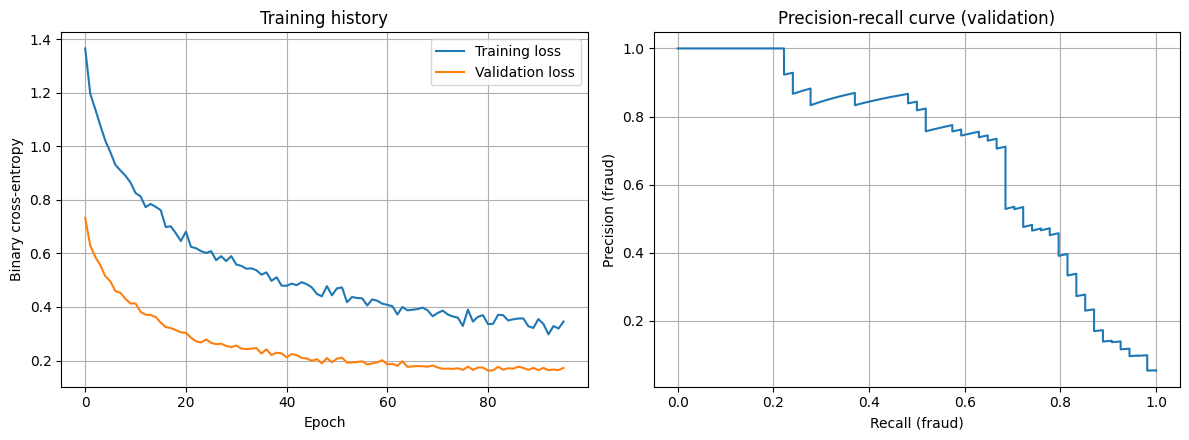

In [12]:
# Program 32: Binary cross-entropy neural network for fraud detection

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, roc_auc_score, log_loss, precision_recall_curve)
from tensorflow import keras
from tensorflow.keras import layers

X, y = make_classification(n_samples=5000, n_features=12, n_informative=6,
                           n_redundant=2, weights=[0.95, 0.05], flip_y=0.01,
                           random_state=32)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=32)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25,
                                              stratify=y_train, random_state=32)

scaler = StandardScaler().fit(X_fit)
Xf = scaler.transform(X_fit)
Xv = scaler.transform(X_val)
Xte = scaler.transform(X_test)

keras.utils.set_random_seed(32)
model = keras.Sequential([
    layers.Input(shape=(X.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc")])

n_pos = y_fit.sum()
n_neg = len(y_fit) - n_pos
class_weight = {0: 1.0, 1: n_neg / n_pos}

early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                      restore_best_weights=True)
history = model.fit(Xf, y_fit, validation_data=(Xv, y_val), epochs=300,
                    batch_size=64, class_weight=class_weight,
                    callbacks=[early], verbose=0)

print("Epochs run:", len(history.history["loss"]))
print("Final training loss:", round(history.history["loss"][-1], 4))
print("Best validation loss:", round(min(history.history["val_loss"]), 4))

p_val = model.predict(Xv, verbose=0).ravel()
precision, recall, thresholds = precision_recall_curve(y_val, p_val)
f1_curve = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
best_idx = np.argmax(f1_curve[:-1])
threshold = thresholds[best_idx]
print("Threshold chosen on validation data (maximises F1):", round(threshold, 4))

p_test = model.predict(Xte, verbose=0).ravel()
y_pred = (p_test >= threshold).astype(int)

print("Test binary cross-entropy (log loss):", round(log_loss(y_test, p_test), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, p_test), 4))
print("Test precision (fraud):", round(precision_score(y_test, y_pred), 4))
print("Test recall (fraud):", round(recall_score(y_test, y_pred), 4))
print("Test F1-score (fraud):", round(f1_score(y_test, y_pred), 4))

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Confusion matrix (test):")
print("              Predicted legit  Predicted fraud")
print(f"Actual legit  {tn:>15}  {fp:>15}")
print(f"Actual fraud  {fn:>15}  {tp:>15}")

print("Accuracy on test (reference only):", round((tp + tn) / len(y_test), 4))
print("Accuracy alone can look high on imbalanced data;")
print("precision, recall and F1 for the fraud class are the meaningful measures.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].set_title("Training history")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(recall, precision)
axes[1].set_xlabel("Recall (fraud)")
axes[1].set_ylabel("Precision (fraud)")
axes[1].set_title("Precision-recall curve (validation)")
axes[1].grid(True)
plt.tight_layout()
plt.show()